In [1]:
from nilearn import image, plotting

import numpy as np

import seaborn as sns

import os

In [2]:
results_dir = os.path.join('..', 'results', 'nilearn')

In [3]:

# initialize images as empty lists
images = []

# find all sub- folders in results_dir
sub_folders = [f.path for f in os.scandir(results_dir) if f.is_dir()]

for sub_folder in sub_folders:

    sub_data= os.path.join(sub_folder, 'ses-01')
    # get all nii.gz files in the sub_folder
    nii_files = [f.path for f in os.scandir(sub_data) if f.is_file() and f.name.endswith('.nii.gz')]

    print(f'Processing {sub_folder} with {len(nii_files)} nii.gz files')
    
    images.extend(nii_files)



Processing ../results/nilearn/sub-08 with 1 nii.gz files
Processing ../results/nilearn/sub-01 with 1 nii.gz files
Processing ../results/nilearn/sub-06 with 1 nii.gz files
Processing ../results/nilearn/sub-07 with 1 nii.gz files
Processing ../results/nilearn/sub-09 with 1 nii.gz files
Processing ../results/nilearn/sub-10 with 1 nii.gz files
Processing ../results/nilearn/sub-05 with 1 nii.gz files
Processing ../results/nilearn/sub-02 with 1 nii.gz files
Processing ../results/nilearn/sub-03 with 1 nii.gz files
Processing ../results/nilearn/sub-04 with 1 nii.gz files


In [4]:
# load all images
images = [image.load_img(img) for img in images]

In [5]:
# absolute values of each image
images = [image.math_img('np.abs(img)', img=img) for img in images]
# average across all images
mean_image = image.mean_img(images)



/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_54865/1532357084.py:4: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  mean_image = image.mean_img(images)


In [6]:
# smooth the image
mean_coef_img = image.smooth_img(mean_image, fwhm=6)

# only keep clusters larger than 100 voxels
mean_coef_img_cl = image.threshold_img(mean_coef_img,cluster_threshold=100, threshold=0.0001)



/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_54865/1725126465.py:5: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  mean_coef_img_cl = image.threshold_img(mean_coef_img,cluster_threshold=100, threshold=0.0001)


/Users/brunoleitao/anaconda3/envs/mvpa/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:868: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)



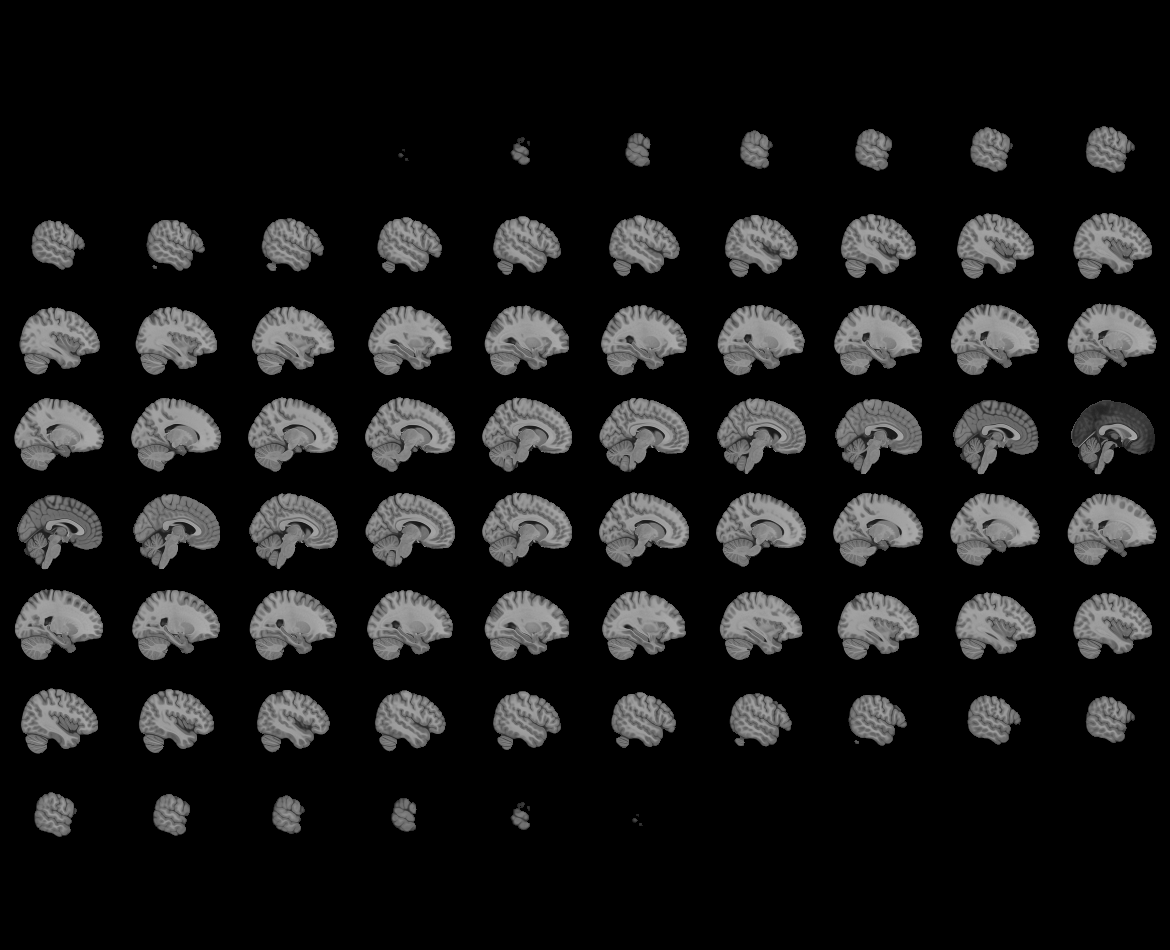
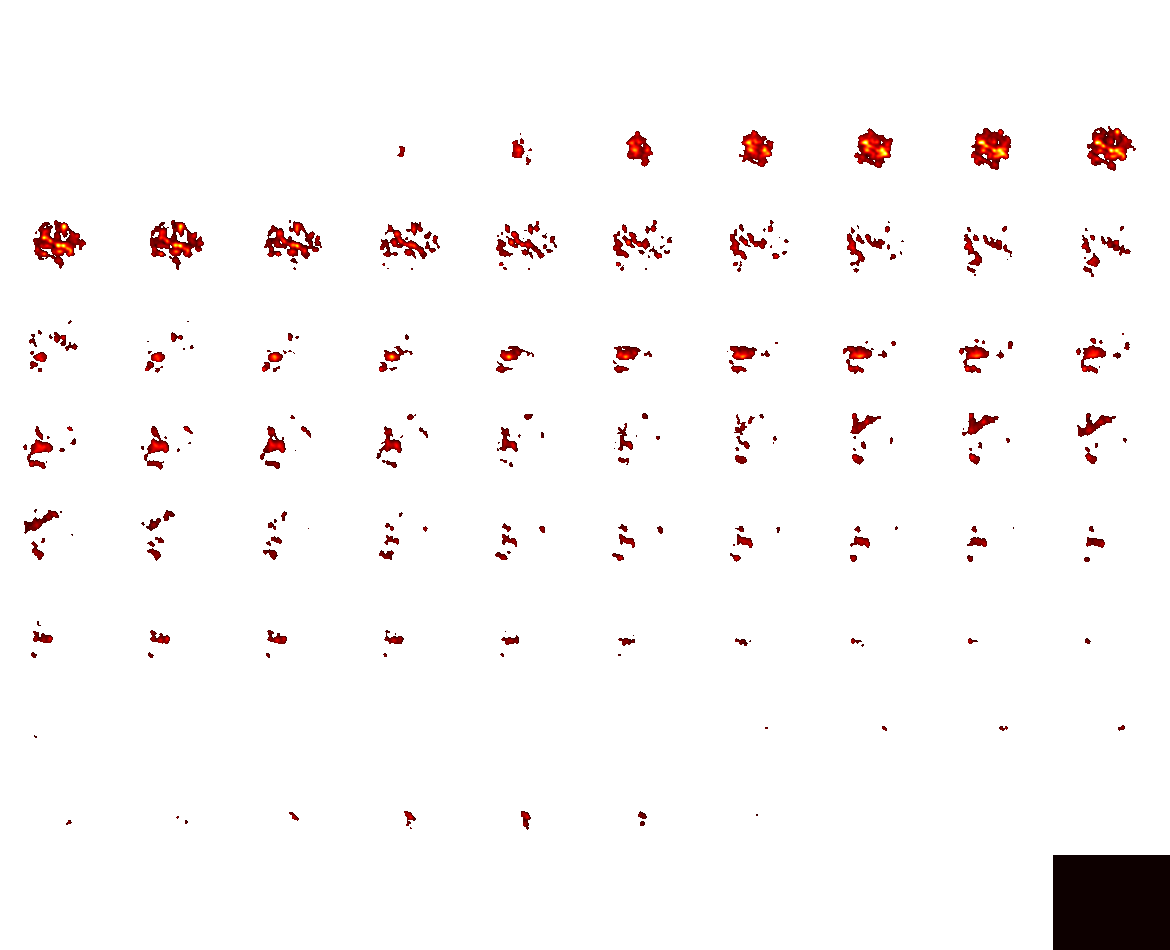

In [7]:
# plot using view_img
# add right left orientation
plotting.view_img(mean_coef_img_cl, colorbar=True, title='Mean Coefficients', )


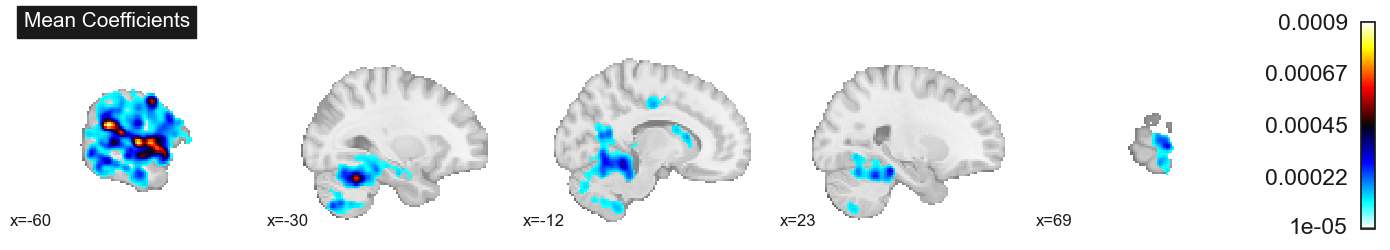

In [23]:
# prepare a figure with 3 columns
sns.set(style='white', font_scale=1.5)
plotting.plot_stat_map(mean_coef_img_cl, title='Mean Coefficients', colorbar=True, display_mode='x', cut_coords=5, threshold=1e-5)

# Confusion Matrix

In [9]:

# initialize images as empty lists
cm = []

# find all sub- folders in results_dir
sub_folders = [f.path for f in os.scandir(results_dir) if f.is_dir()]

for sub_folder in sub_folders:

    sub_data= os.path.join(sub_folder, 'ses-01')
    # get all nii.gz files in the sub_folder
    cm_files = [f.path for f in os.scandir(sub_data) if f.is_file() and f.name.endswith('.csv')]

    print(f'Processing {sub_folder} with {len(cm_files)} csv files')
    
    cm.extend(cm_files)


Processing ../results/nilearn/sub-08 with 1 csv files
Processing ../results/nilearn/sub-01 with 1 csv files
Processing ../results/nilearn/sub-06 with 1 csv files
Processing ../results/nilearn/sub-07 with 1 csv files
Processing ../results/nilearn/sub-09 with 1 csv files
Processing ../results/nilearn/sub-10 with 1 csv files
Processing ../results/nilearn/sub-05 with 1 csv files
Processing ../results/nilearn/sub-02 with 1 csv files
Processing ../results/nilearn/sub-03 with 1 csv files
Processing ../results/nilearn/sub-04 with 1 csv files


In [16]:
# load data from cm_Files
cm_data = []
for cm_file in cm:
    data = np.loadtxt(cm_file, delimiter=',', skiprows=1, usecols=range(1, 10))
    # append data to cm_data
    cm_data.append(data)

    # get the labels in the first row
    labels = np.loadtxt(cm_file, delimiter=',', max_rows=1, dtype=str)



cm_data = np.concatenate(cm_data, axis=0)

In [19]:
# compute the mean and standard deviation of the data
mean_cm = np.mean(cm_data, axis=0)
std_cm = np.std(cm_data, axis=0)


In [20]:
mean_cm = mean_cm/16 * 100  # convert to percentage
std_cm = std_cm/16 * 100  # convert to percentage


Text(47.24999999999999, 0.5, 'True')

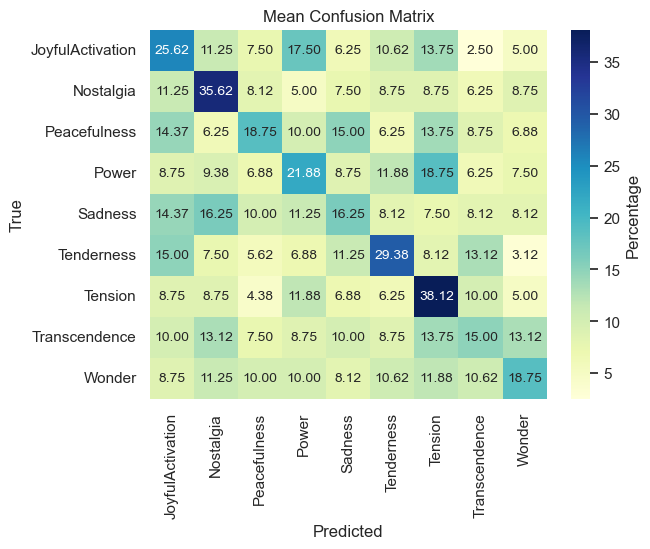

In [21]:
#using seaborn to plot the mean of the confusion matrix
sns.set(style="whitegrid")
ax = sns.heatmap(mean_cm, annot=True, cmap="YlGnBu", xticklabels=labels[1:], yticklabels=labels[1:],
                 fmt=".2f", cbar_kws={"label": "Percentage"}, annot_kws={"size": 10})

ax.set_title('Mean Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')